# Assignment 4: CIFAR-10 Energy and Diffusion Models

I use the same `helper_lib` code as the training scripts and FastAPI service to inspect the architectures, train both models, save checkpoints, and generate images.

**Run record:** I completed this run on 2026-11-12 with an Apple M1 Pro MPS device, using all 50,000 CIFAR-10 training images per epoch. The EBM ran for 10 epochs and diffusion for 50 epochs. The 10,000-image test split was used for diffusion noise-prediction checks and did not update model weights. I used an existing CIFAR-10 cache. The data-location setting below accepts `CIFAR10_DATA_DIR` or downloads into `data/` so the notebook can be rerun elsewhere; the saved outputs are from the completed run. The optional short-check notebook has no saved outputs.

In [1]:
from pathlib import Path
import os
import copy
import matplotlib.pyplot as plt
import torch
from torchvision.utils import make_grid, save_image

from training_common import build_cifar_loader, calculate_channel_stats, choose_device, set_seed
from helper_lib.model import get_model
from helper_lib.trainer import train_ebm, train_diffusion
from helper_lib.generator import generate_samples
from helper_lib.checkpoint import (
    save_ebm_checkpoint, save_diffusion_checkpoint,
    load_ebm_checkpoint, load_diffusion_checkpoint,
)

ROOT = Path.cwd()
if not (ROOT / "helper_lib").is_dir():
    raise RuntimeError("Open Jupyter from the Assignment 4/api directory.")
DATA_DIR = Path(os.environ.get("CIFAR10_DATA_DIR", ROOT / "data")).expanduser()
MODEL_DIR = ROOT / "models"
SAMPLES_DIR = ROOT / "outputs" / "samples"
MODEL_DIR.mkdir(exist_ok=True)
SAMPLES_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
OFFLINE = (DATA_DIR / "cifar-10-batches-py").is_dir()
QUICK_CHECK = False   # Short functional check; use False for full training.
DEVICE = choose_device("auto")
set_seed(SEED)
print("Device:", DEVICE, "| mode:", "quick check" if QUICK_CHECK else "full training")

Device: mps | mode: full training


## 1. Check the two architectures

The EBM turns an RGB image into **one energy score**, while the diffusion U-Net returns a noise estimate with the **same shape as the image**. Both are unconditional: CIFAR-10 class labels are present but are not fed to either model.

In [2]:
ebm = get_model("EBM", base_channels=16).to(DEVICE)
diffusion = get_model("Diffusion", base_width=16, block_depth=1).to(DEVICE)
probe_images = torch.rand(2, 3, 32, 32, device=DEVICE)
probe_noise_variance = torch.rand(2, 1, 1, 1, device=DEVICE)
with torch.no_grad():
    energy_shape = tuple(ebm(probe_images).shape)
    noise_shape = tuple(diffusion(probe_images, probe_noise_variance).shape)
print("Input:", tuple(probe_images.shape))
print("EBM energy:", energy_shape)
print("Diffusion predicted noise:", noise_shape)
assert energy_shape == (2, 1)
assert noise_shape == tuple(probe_images.shape)

Input: (2, 3, 32, 32)
EBM energy: (2, 1)
Diffusion predicted noise: (2, 3, 32, 32)


## 2. Load and inspect CIFAR-10

The two training loops need different pixel scales. `ToTensor()` maps image bytes to `[0,1]`; the EBM loader then applies `(x-0.5)/0.5`, giving `[-1,1]` for its Langevin sampler. Diffusion keeps the loader output in `[0,1]` and normalizes with measured training-set channel means and standard deviations inside its loss. The test split is reserved for a diffusion noise-prediction check; it is not used to update weights.

Training examples: 50000
Held-out examples used for proxy loss: 10000
EBM batch: (128, 3, 32, 32) range: (-1.0, 1.0)
Diffusion mean: (0.4913996786151961, 0.48215840839460783, 0.44653091444546555) std: (0.24703223246328196, 0.2434851280000557, 0.26158784172796445)


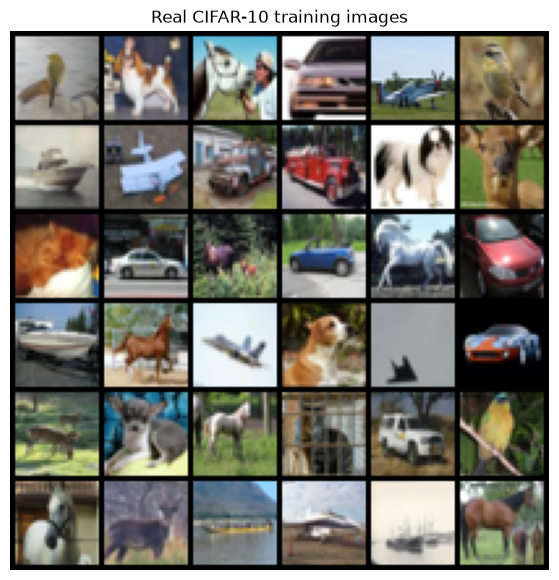

In [3]:
TRAIN_LIMIT = 512 if QUICK_CHECK else 0  # 0 means all 50,000 training images.
VAL_LIMIT = 128 if QUICK_CHECK else 0  # 0 means all 10,000 test images.
EBM_BATCH_SIZE = 32 if QUICK_CHECK else 128
DIFF_BATCH_SIZE = 16 if QUICK_CHECK else 64

train_ebm_loader, ebm_dataset = build_cifar_loader(
    DATA_DIR, train=True, batch_size=EBM_BATCH_SIZE,
    image_range="minus_one_one", limit=TRAIN_LIMIT, offline=OFFLINE,
)
train_diff_loader, diffusion_dataset = build_cifar_loader(
    DATA_DIR, train=True, batch_size=DIFF_BATCH_SIZE,
    image_range="zero_one", limit=TRAIN_LIMIT, offline=True,
)
val_diff_loader, _ = build_cifar_loader(
    DATA_DIR, train=False, batch_size=DIFF_BATCH_SIZE,
    image_range="zero_one", limit=VAL_LIMIT, offline=OFFLINE,
)
channel_mean, channel_std = calculate_channel_stats(diffusion_dataset, limit=TRAIN_LIMIT)
real_ebm, labels = next(iter(train_ebm_loader))
print("Training examples:", len(train_ebm_loader.dataset))
print("Held-out examples used for proxy loss:", len(val_diff_loader.dataset))
print("EBM batch:", tuple(real_ebm.shape), "range:", (float(real_ebm.min()), float(real_ebm.max())))
print("Diffusion mean:", channel_mean, "std:", channel_std)
real_grid = make_grid((real_ebm[:36] + 1) / 2, nrow=6)
plt.figure(figsize=(7, 7))
plt.imshow(real_grid.permute(1, 2, 0))
plt.title("Real CIFAR-10 training images")
plt.axis("off")
plt.show()

## 3. Train the energy model

For each batch, the training loop draws negative images from a replay buffer, adds a small amount of noise, and performs Langevin steps on **the image tensor** to lower its energy. During those steps, model weights are not optimized. The loss then lowers energy on real images and raises it on the sampled negatives, with a squared-energy regularizer to keep scores controlled. `alpha`, `langevin_steps`, `step_size`, and `noise_std` are therefore part of the model's behavior, not decoration. Each completed epoch saves an actual checkpoint for the API.

In [4]:
EBM_EPOCHS = 1 if QUICK_CHECK else 10
EBM_LANGEVIN_STEPS = 2 if QUICK_CHECK else 60
EBM_MAX_BATCHES = 2 if QUICK_CHECK else None
EBM_CHECKPOINT = MODEL_DIR / ("ebm_cifar10_smoke.pt" if QUICK_CHECK else "ebm_cifar10.pt")
ebm_history = []
ebm_config = {
    "seed": SEED, "batch_size": EBM_BATCH_SIZE, "train_limit": TRAIN_LIMIT,
    "epochs": EBM_EPOCHS, "langevin_steps": EBM_LANGEVIN_STEPS,
    "step_size": 10.0, "noise_std": 0.005, "alpha": 0.1,
    "max_batches": EBM_MAX_BATCHES or 0,
}

def on_ebm_epoch(model, record):
    save_ebm_checkpoint(
        EBM_CHECKPOINT, model, epoch=int(record["epoch"]),
        training_mode="smoke" if QUICK_CHECK else "full",
        history=ebm_history, config=ebm_config,
    )
    print(f"EBM epoch {int(record['epoch'])}: loss={record['loss']:.4f}, "
          f"real_energy={record['real_energy']:.4f}, fake_energy={record['fake_energy']:.4f}")

train_ebm(
    ebm, train_ebm_loader, device=DEVICE, epochs=EBM_EPOCHS,
    alpha=0.1, langevin_steps=EBM_LANGEVIN_STEPS,
    step_size=10.0, noise_std=0.005,
    max_batches=EBM_MAX_BATCHES, history=ebm_history,
    epoch_callback=on_ebm_epoch,
)
print("Saved:", EBM_CHECKPOINT)

EBM epoch 1: loss=-0.0014, real_energy=0.0040, fake_energy=0.0059


EBM epoch 2: loss=0.0000, real_energy=-0.0019, fake_energy=-0.0017


EBM epoch 3: loss=-0.0003, real_energy=0.0010, fake_energy=0.0014


EBM epoch 4: loss=-0.0002, real_energy=0.0009, fake_energy=0.0012


EBM epoch 5: loss=0.0002, real_energy=0.0006, fake_energy=0.0005


EBM epoch 6: loss=0.0001, real_energy=0.0001, fake_energy=0.0001


EBM epoch 7: loss=-0.0002, real_energy=0.0004, fake_energy=0.0006


EBM epoch 8: loss=0.0001, real_energy=0.0000, fake_energy=0.0000


EBM epoch 9: loss=0.0003, real_energy=0.0001, fake_energy=-0.0001


EBM epoch 10: loss=0.0002, real_energy=0.0003, fake_energy=0.0002
Saved: /Users/luyan/Desktop/Applied Generative AI/Assignment 4/api/models/ebm_cifar10.pt


## 4. Reload and sample from the EBM

Reloading checks that the API can use the saved architecture and weights. Generation starts from random RGB pixels and **changes the pixels** using energy gradients; it does not update the model weights. Compare these images to the real grid above. A small loss or low energy by itself does not prove that samples look realistic.

Checkpoint metadata: {'epoch': 10, 'training_mode': 'full', 'image_shape': (3, 32, 32), 'config': {'seed': 42, 'batch_size': 128, 'train_limit': 0, 'epochs': 10, 'langevin_steps': 60, 'step_size': 10.0, 'noise_std': 0.005, 'alpha': 0.1, 'max_batches': 0}, 'last_metrics': {'epoch': 10.0, 'examples_seen': 50000.0, 'loss': 0.00016181302139535548, 'contrastive': 8.991082347929478e-05, 'regularizer': 7.190219868207351e-05, 'real_energy': 0.000337584266923368, 'fake_energy': 0.00024767344538122415}}


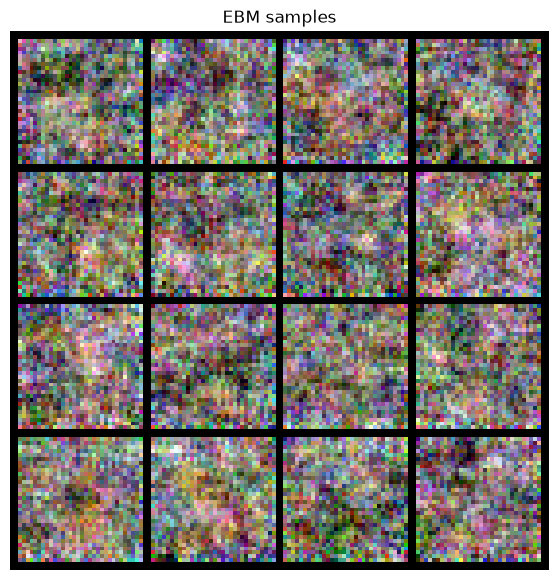

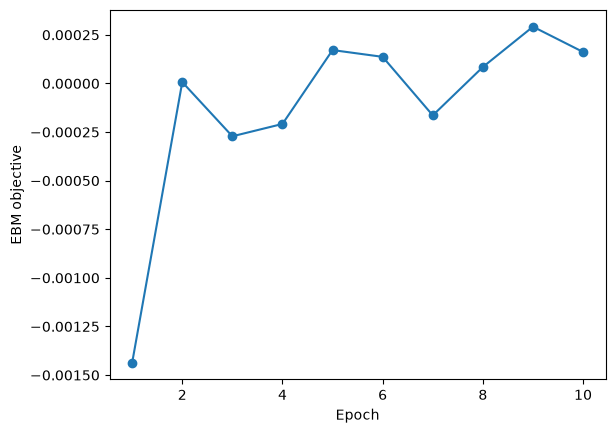

In [5]:
ebm_for_api, ebm_metadata = load_ebm_checkpoint(EBM_CHECKPOINT)
print("Checkpoint metadata:", ebm_metadata)
ebm_grid = generate_samples(
    ebm_for_api, "cpu", num_samples=16, seed=SEED,
    ebm_steps=2 if QUICK_CHECK else 60,
)
save_image(ebm_grid, SAMPLES_DIR / "ebm_grid.png")
plt.figure(figsize=(7, 7))
plt.imshow(ebm_grid.permute(1, 2, 0))
plt.title("EBM samples (quick check)" if QUICK_CHECK else "EBM samples")
plt.axis("off")
plt.show()
plt.plot([r["epoch"] for r in ebm_history], [r["loss"] for r in ebm_history], marker="o")
plt.xlabel("Epoch")
plt.ylabel("EBM objective")
plt.show()

## 5. Train the diffusion model

For each clean image, the training loop samples a random noise tensor and a random diffusion time. The offset-cosine schedule mixes clean signal and noise; the U-Net predicts that exact noise and uses mean absolute error (`L1Loss`). The exponential moving average (EMA) model follows the trained weights smoothly and is the version saved for image generation. The held-out loss checks noise prediction on unseen CIFAR-10 images, not visual quality. The callback saves both live and EMA weights at each completed epoch.

In [6]:
DIFF_EPOCHS = 1 if QUICK_CHECK else 50
DIFF_MAX_BATCHES = 2 if QUICK_CHECK else None
DIFF_CHECKPOINT = MODEL_DIR / ("diffusion_cifar10_smoke.pt" if QUICK_CHECK else "diffusion_cifar10.pt")
diffusion_ema = copy.deepcopy(diffusion).to(DEVICE)
diffusion_history = []
diff_config = {
    "seed": SEED, "batch_size": DIFF_BATCH_SIZE, "train_limit": TRAIN_LIMIT,
    "val_limit": VAL_LIMIT, "epochs": DIFF_EPOCHS,
    "learning_rate": 1e-3, "ema_decay": 0.995,
    "max_batches": DIFF_MAX_BATCHES or 0,
}

def on_diffusion_epoch(model, ema_model, record):
    save_diffusion_checkpoint(
        DIFF_CHECKPOINT, model, ema_model,
        epoch=int(record["epoch"]),
        training_mode="smoke" if QUICK_CHECK else "full",
        history=diffusion_history,
        normalizer_mean=channel_mean, normalizer_std=channel_std,
        min_signal_rate=0.02, max_signal_rate=0.95,
        config=diff_config,
    )
    print(f"Diffusion epoch {int(record['epoch'])}: train L1={record['train_loss']:.4f}, "
          f"held-out L1={record['val_loss']:.4f}")

train_diffusion(
    diffusion, train_diff_loader, device=DEVICE, epochs=DIFF_EPOCHS,
    normalizer_mean=channel_mean, normalizer_std=channel_std,
    min_signal_rate=0.02, max_signal_rate=0.95,
    ema_model=diffusion_ema, ema_decay=0.995,
    val_loader=val_diff_loader,
    max_batches=DIFF_MAX_BATCHES,
    history=diffusion_history, epoch_callback=on_diffusion_epoch,
)
print("Saved:", DIFF_CHECKPOINT)

Diffusion epoch 1: train L1=0.2445, held-out L1=0.2071


Diffusion epoch 2: train L1=0.1826, held-out L1=0.1788


Diffusion epoch 3: train L1=0.1878, held-out L1=0.2304


Diffusion epoch 4: train L1=0.1969, held-out L1=0.1914


Diffusion epoch 5: train L1=0.1868, held-out L1=0.1859


Diffusion epoch 6: train L1=0.1839, held-out L1=0.1780


... (40 outputs left out)

Diffusion epoch 47: train L1=0.2056, held-out L1=0.2021


Diffusion epoch 48: train L1=0.1999, held-out L1=0.1976


Diffusion epoch 49: train L1=0.1953, held-out L1=0.1937


Diffusion epoch 50: train L1=0.1923, held-out L1=0.1907
Saved: /Users/luyan/Desktop/Applied Generative AI/Assignment 4/api/models/diffusion_cifar10.pt


## 6. Reload and sample from diffusion

Sampling begins with Gaussian noise. At each reverse step, the U-Net estimates the noise, reconstructs a cleaner image, and moves to the next lower-noise level. The loaded model below uses the saved EMA weights. The seed fixes the starting noise so successive checkpoints can be compared fairly; the number of reverse steps controls time and often image quality.

Checkpoint metadata: {'epoch': 50, 'training_mode': 'full', 'image_shape': (3, 32, 32), 'config': {'seed': 42, 'batch_size': 64, 'train_limit': 0, 'val_limit': 0, 'epochs': 50, 'learning_rate': 0.001, 'ema_decay': 0.995, 'max_batches': 0}, 'last_metrics': {'epoch': 50.0, 'examples_seen': 50000.0, 'train_loss': 0.19231016637802123, 'val_loss': 0.19073342835903168}, 'normalizer_mean': (0.4913996786151961, 0.48215840839460783, 0.44653091444546555), 'normalizer_std': (0.24703223246328196, 0.2434851280000557, 0.26158784172796445), 'min_signal_rate': 0.02, 'max_signal_rate': 0.95, 'base_width': 16, 'block_depth': 1}


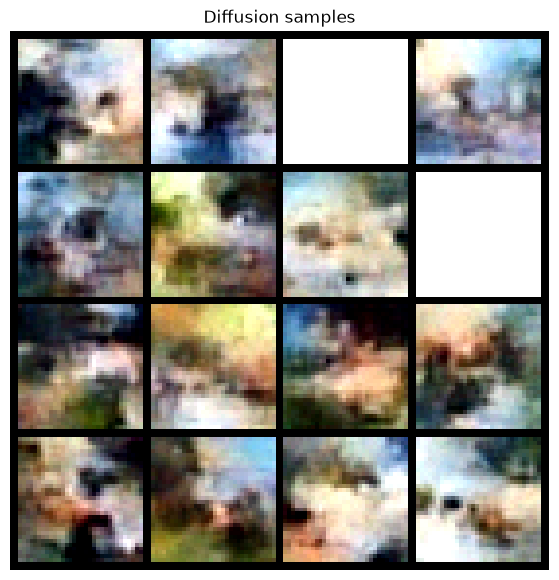

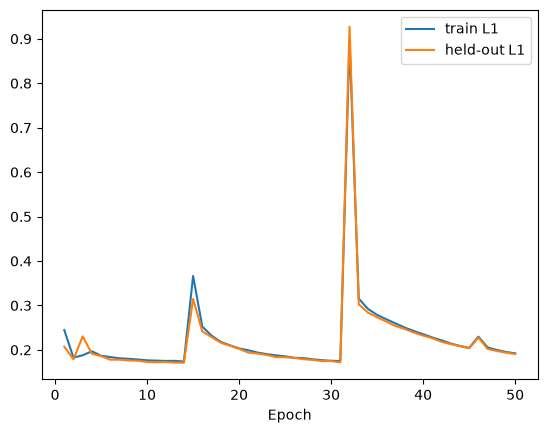

In [7]:
diffusion_for_api, diffusion_metadata = load_diffusion_checkpoint(DIFF_CHECKPOINT)
print("Checkpoint metadata:", diffusion_metadata)
diff_grid = generate_samples(
    diffusion_for_api, "cpu", num_samples=16, seed=SEED,
    diffusion_steps=10 if QUICK_CHECK else 100,
    normalizer_mean=channel_mean, normalizer_std=channel_std,
)
save_image(diff_grid, SAMPLES_DIR / "diffusion_grid.png")
plt.figure(figsize=(7, 7))
plt.imshow(diff_grid.permute(1, 2, 0))
plt.title("Diffusion samples (quick check)" if QUICK_CHECK else "Diffusion samples")
plt.axis("off")
plt.show()
epochs = [r["epoch"] for r in diffusion_history]
plt.plot(epochs, [r["train_loss"] for r in diffusion_history], label="train L1")
plt.plot(epochs, [r["val_loss"] for r in diffusion_history], label="held-out L1")
plt.xlabel("Epoch")
plt.legend()
plt.show()

## 7. What the checks mean

- The shape assertions catch channel and U-Net dimension mistakes before long training.
- Checkpoint reloading catches mismatches between training and API architectures. The API should be restarted after writing new checkpoints, so it reloads the new weights.
- Visual grids show whether generation is plausible; the training and held-out L1 losses only measure noise-prediction error. I did not compute FID, Inception Score, or run a human study.
- The EBM's contrastive loss and real/fake energy values help diagnose training, but low energy can still occur on poor images. The EBM's replay buffer is training state held in memory and is not restored from the inference checkpoint.
- In `QUICK_CHECK` mode, both checkpoints are marked `training_mode="smoke"`. Use full training and inspect generated grids before presenting them as final model results.
- The API returns images from models trained on the ten CIFAR-10 classes together; neither endpoint accepts a class label. API usage and Docker commands are in `README.md`.

## Results and limitations

- The saved EBM checkpoint is epoch 10/10. Its sample grid remains visually close to colored texture noise even though Langevin sampling lowers the model energy.
- The saved diffusion checkpoint is epoch 50/50. Its last train and held-out noise-prediction L1 losses are 0.1923 and 0.1907. Training had loss spikes, and the final images are blurry. These losses do not measure image realism.
- A separate epoch-31 comparison checkpoint is saved as `models/diffusion_cifar10_epoch31_candidate.pt` with held-out L1 0.1719. The historical lowest held-out L1 was at epoch 14, but that epoch's weights were overwritten by the notebook callback; the epoch-31 file is not claimed as the global best checkpoint. The Docker API serves the final epoch-50 checkpoint.
- I rebuilt the Docker image with the full checkpoints. `/health` reported both models ready, and the EBM and diffusion generation routes each returned a 32 × 32 PNG. I did not calculate FID, Inception Score, or run a human quality study.